# D1ECD – Estatística para Ciência de Dados
## Atividade Avaliativa 03 – Regressão Linear e Correlação

**Nome:** Rodrigo Gimenes Rodrigues  
**Matrícula:** CP3071782  
**Curso:** Especialização em Ciência de Dados  
**Período/Ano:** 2026/2  
**Campus:** Campinas  
**Turno:** EAD  
**Professor:** Kakimoto


## Conjunto de dados

Investimento mensal em marketing digital (X, em milhares de R$) e vendas do mês (Y, em milhares de unidades), para 12 meses.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

dados = {
    'Mes': list(range(1, 13)),
    'Investimento': [10, 12, 15, 18, 20, 22, 25, 30, 32, 35, 40, 45],
    'Vendas': [15, 19, 22, 26, 30, 31, 37, 42, 45, 48, 55, 60],
}
df = pd.DataFrame(dados)
X = df['Investimento']
Y = df['Vendas']
df

,Mes,Investimento,Vendas
0,1,10,15
1,2,12,19
2,3,15,22
3,4,18,26
4,5,20,30
5,6,22,31
6,7,25,37
7,8,30,42
8,9,32,45
9,10,35,48


## Parte 1 – EDA, correlação, regressão e diagnóstico

### Estatísticas descritivas

In [2]:
print(df[['Investimento', 'Vendas']].describe())
print()
print('Mediana Investimento:', X.median())
print('Mediana Vendas:', Y.median())

       Investimento     Vendas
count     12.000000  12.000000
mean      25.333333  35.833333
std       11.178985  14.414849
min       10.000000  15.000000
25%       17.250000  25.000000
50%       23.500000  34.000000
75%       32.750000  45.750000
max       45.000000  60.000000

Mediana Investimento: 23.5
Mediana Vendas: 34.0


### Gráfico de dispersão

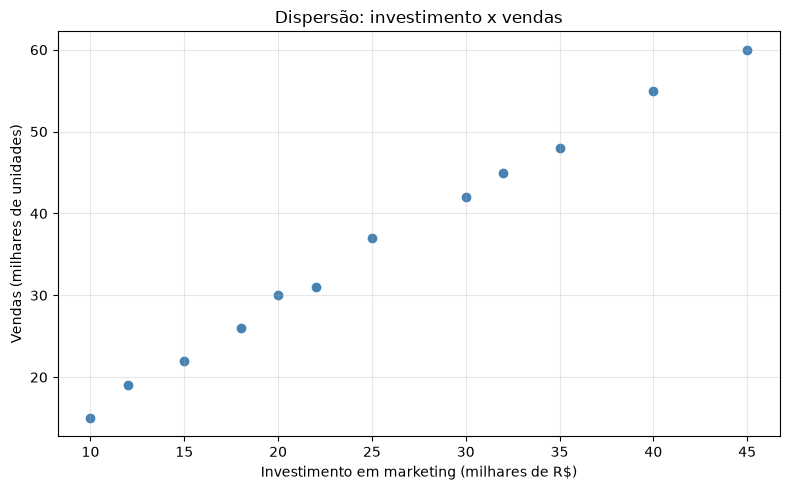

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='steelblue')
plt.xlabel('Investimento em marketing (milhares de R$)')
plt.ylabel('Vendas (milhares de unidades)')
plt.title('Dispersão: investimento x vendas')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Correlação de Pearson

In [4]:
r, p_corr = stats.pearsonr(X, Y)
print('r =', round(r, 4))
print('p-valor =', p_corr)

r = 0.9984
p-valor = 9.372745475820718e-14


O r deu cerca de **0.9984**, bem perto de 1. Ou seja, associação linear positiva e bem forte: quando o investimento sobe, as vendas também sobem. O p-valor ficou praticamente zero (≪ 0,05), então a correlação é estatisticamente significativa.

### Regressão linear simples

In [5]:
X1 = sm.add_constant(X)
modelo = sm.OLS(Y, X1).fit()
print(modelo.summary())
print()
print('β0 (intercepto) =', round(modelo.params['const'], 4))
print('β1 (inclinação) =', round(modelo.params['Investimento'], 4))
print('R² =', round(modelo.rsquared, 4))

                            OLS Regression Results                            
Dep. Variable:                 Vendas   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     3038.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           9.37e-14
Time:                        15:54:56   Log-Likelihood:                -14.207
No. Observations:                  12   AIC:                             32.41
Df Residuals:                      10   BIC:                             33.38
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.2207      0.642      5.014   



β0 (intercepto) = 3.2207
β1 (inclinação) = 1.2873
R² = 0.9967


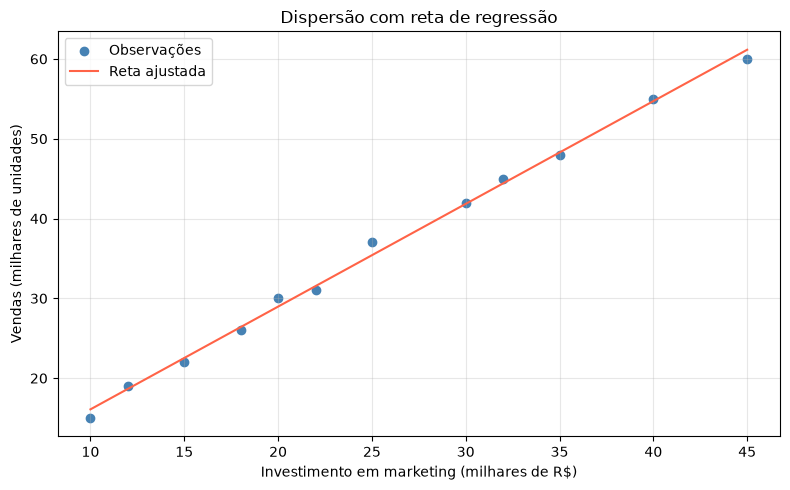

In [6]:
b0 = modelo.params['const']
b1 = modelo.params['Investimento']

plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='steelblue', label='Observações')
xs = np.linspace(X.min(), X.max(), 100)
plt.plot(xs, b0 + b1 * xs, color='tomato', label='Reta ajustada')
plt.xlabel('Investimento em marketing (milhares de R$)')
plt.ylabel('Vendas (milhares de unidades)')
plt.title('Dispersão com reta de regressão')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

A equação ficou aproximadamente **Ŷ = 3.22 + 1.29 X**.  
R² ≈ **0.9967**, então quase toda a variação das vendas na amostra é explicada pelo investimento.

### Predição (X = 28) e resíduos

In [7]:
pred_28 = modelo.predict([1, 28])[0]
print('Vendas previstas para X = 28:', round(pred_28, 2))

y_hat = modelo.fittedvalues
residuos = modelo.resid
print()
print(pd.DataFrame({'Y': Y, 'Y_hat': y_hat, 'residuo': residuos}))

Vendas previstas para X = 28: 39.27

     Y      Y_hat   residuo
0   15  16.094083 -1.094083
1   19  18.668768  0.331232
2   22  22.530795 -0.530795
3   26  26.392823 -0.392823
4   30  28.967507  1.032493
5   31  31.542192 -0.542192
6   37  35.404219  1.595781
7   42  41.840931  0.159069
8   45  44.415616  0.584384
9   48  48.277643 -0.277643
10  55  54.714355  0.285645
11  60  61.151067 -1.151067


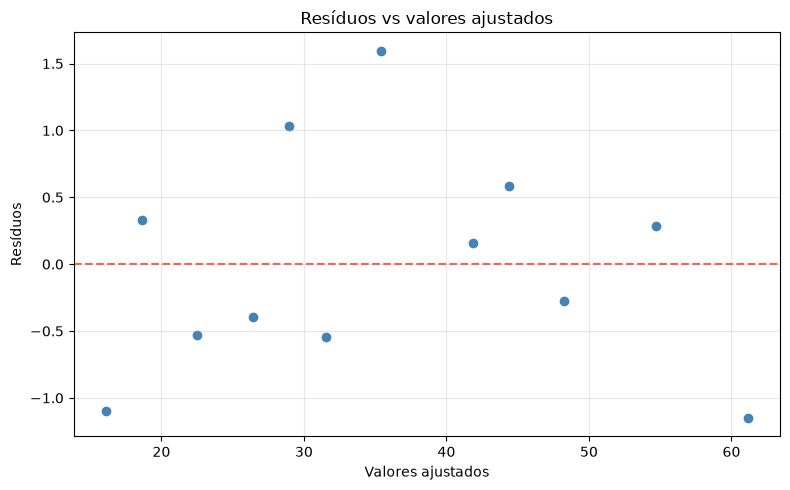

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(y_hat, residuos, color='steelblue')
plt.axhline(0, color='tomato', linestyle='--')
plt.xlabel('Valores ajustados')
plt.ylabel('Resíduos')
plt.title('Resíduos vs valores ajustados')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Parte 2 – Interpretação

**Correlação:** o r ≈ 0,998 indica relação linear positiva e muito forte entre investimento e vendas. Na prática, os meses com mais marketing também foram os de mais venda, de forma bem alinhada.

**Equação da reta:** o β1 ≈ 1,29 quer dizer que, em média, cada R$ 1 mil a mais de investimento está associado a cerca de 1,29 mil unidades a mais de venda. O β0 ≈ 3,22 seria a venda esperada com investimento zero. Aqui essa interpretação prática é fraca, porque zero marketing fica fora do intervalo observado (10 a 45) e o negócio quase certamente não opera assim.

**R²:** cerca de 99,7% da variabilidade das vendas é explicada pelo investimento. Para estimativa dentro da faixa dos dados, o ajuste está muito bom. Com só 12 pontos e uma relação quase perfeita, ainda assim vale cuidado para não extrapolar demais.

**Resíduos:** o gráfico fica espalhado em torno de zero, sem curva óbvia nem funil claro de heterocedasticidade. Com amostra pequena é difícil afirmar com certeza, mas visualmente não aparece padrão forte de problema.

**Decisão (X = 28):** a previsão fica em torno de **39,3 mil unidades**. Como 28 mil de investimento está dentro da faixa histórica, a estimativa é razoável. Eu recomendaria à diretoria usar esse valor como referência de planejamento, acompanhando o resultado real do mês e sem assumir que a mesma reta vale para investimentos bem fora do que já foi testado.
